In [1]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/adaptaciones_videojuegos_2016_2025.csv")
df.head()



,id_semilla,titulo,anio,franquicia,tipo_adaptacion,criterio_inclusion,titulo_busqueda_tmdb,fuente_verificacion,estado_revision,estado_busqueda_tmdb,...,recaudacion_usd,generos_tmdb,rating_tmdb,votos_tmdb,rating_imdb,votos_imdb,metascore,rating_rotten_tomatoes,taquilla_omdb,estado_omdb
0,vg_001,Warcraft,2016,Warcraft,pelicula_largometraje,Basada en la franquicia de videojuegos Warcraft,Warcraft,https://en.wikipedia.org/wiki/List_of_films_ba...,pendiente_enriquecimiento_api,coincidencia_anio,...,433677183.0,"Acción, Aventura, Fantasía",6.428,7599,6.7,298522,32.0,29%,"$47,365,290",True
1,vg_002,Ratchet & Clank,2016,Ratchet & Clank,pelicula_largometraje,Basada en el videojuego Ratchet & Clank,Ratchet & Clank,https://en.wikipedia.org/wiki/List_of_films_ba...,pendiente_enriquecimiento_api,coincidencia_anio,...,8800000.0,"Acción, Aventura, Animación, Familia",5.773,699,5.5,12720,29.0,22%,"$8,821,329",True
2,vg_003,The Angry Birds Movie,2016,Angry Birds,pelicula_largometraje,Basada en el videojuego Angry Birds,The Angry Birds Movie,https://en.wikipedia.org/wiki/List_of_films_ba...,pendiente_enriquecimiento_api,coincidencia_anio,...,349779543.0,"Animación, Aventura, Comedia, Familia",6.294,4188,6.3,121382,43.0,44%,"$107,509,366",True
3,vg_004,Assassin's Creed,2016,Assassin's Creed,pelicula_largometraje,Basada en la franquicia de videojuegos Assassi...,Assassin's Creed,https://en.wikipedia.org/wiki/List_of_films_ba...,pendiente_enriquecimiento_api,coincidencia_anio,...,240700000.0,"Acción, Aventura, Ciencia ficción",5.448,8325,5.6,221355,36.0,18%,"$54,647,948",True
4,vg_005,Resident Evil: The Final Chapter,2016,Resident Evil,pelicula_largometraje,Basada en la franquicia de videojuegos Residen...,Resident Evil: The Final Chapter,https://en.wikipedia.org/wiki/List_of_films_ba...,pendiente_enriquecimiento_api,coincidencia_anio,...,312242626.0,"Acción, Terror, Ciencia ficción",6.102,3675,5.5,111048,49.0,39%,"$26,830,068",True


PUNTO 1 **************************************************************************************************************************************

Desempeño comercial: 
Presupuesto estimado, recaudación total, fecha de estreno, popularidad, y comparación con otras adaptaciones de videojuegos o películas familiares del mismo año.

1) Presupuesto estimado, recaudacion total y fecha de estreno de A Minecraft Movie

In [2]:
minecraft = df[df["titulo"] == "A Minecraft Movie"]
minecraft[["titulo", "presupuesto_usd", "recaudacion_usd", "fecha_estreno"]]

,titulo,presupuesto_usd,recaudacion_usd,fecha_estreno
24,A Minecraft Movie,150000000.0,960387780.0,2025-03-31


2) ¿Ganó o perdió plata?

Ganó plata, porque la recaudación (USD 960.387.780) fue mayor que el presupuesto (USD 150.000.000). 
Obtuvo una ganancia de USD 810.387.780.

    IMDb: sitio web de cine que recopila puntuaciones y opiniones de los espectadores.
    TMDB: base de datos de películas que reúne información, puntuaciones y opiniones de los usuarios.

In [3]:
minecraft = df[df["titulo"] == "A Minecraft Movie"]
minecraft[["titulo", "fecha_estreno", "presupuesto_usd", "recaudacion_usd", "ganancia_usd", "retorno", "votos_imdb"]]

#El retorno dice cuántas veces recuperó lo invertido. Por cada dolar que invirtieron ganaron 6,4

KeyError: "['ganancia_usd', 'retorno'] not in index"

3) Popularidad con peliculas del mismo año


Vemos en qué puesto quedó Minecraft.
Uso votos_imdb porque mide cuánta gente votó, y más votos significa que más gente vio la película.



In [4]:
df_2025 = df[df["anio"] == 2025]
df_2025.sort_values("votos_imdb", ascending=False)[["titulo", "votos_imdb", "rating_imdb"]]


,titulo,votos_imdb,rating_imdb
24,A Minecraft Movie,168568,5.6
25,Until Dawn,72750,5.7
26,Five Nights at Freddy's 2,47626,5.1


4) Comparación con otras peliculas del mismo año

Tabla con las películas de 2025 ordenadas por recaudación. Ahí vemos en qué puesto quedó Minecraft.

In [5]:
df_2025 = df[df["anio"] == 2025]
df_2025.sort_values("recaudacion_usd", ascending=False)[["titulo", "presupuesto_usd", "recaudacion_usd", "retorno"]]



KeyError: "['retorno'] not in index"

GRAFICOS DE CADA PUNTO

Grafico: Presupuesto y Recaudación

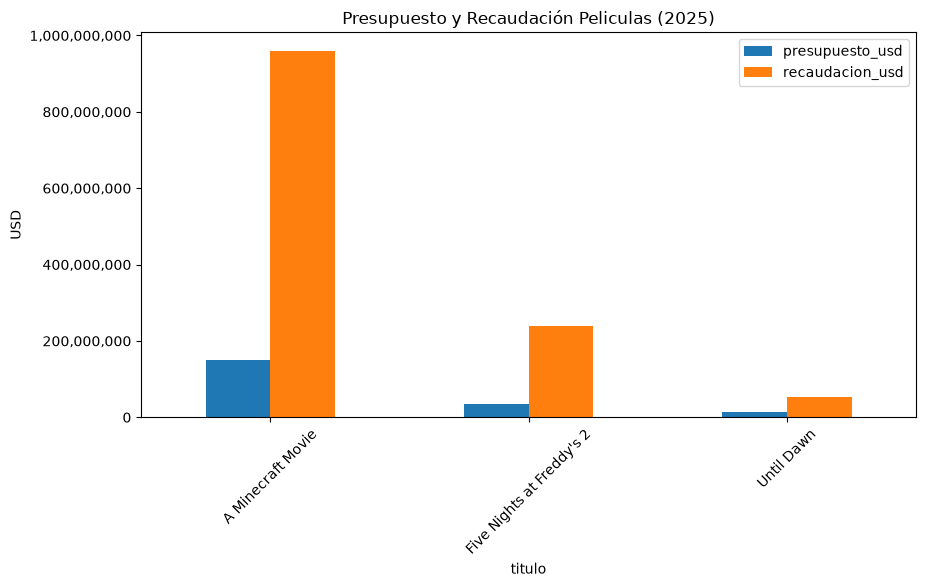

In [6]:
tabla = df_2025.sort_values("recaudacion_usd", ascending=False).head(10).set_index("titulo")[["presupuesto_usd", "recaudacion_usd"]]

tabla.plot(kind="bar", figsize=(10, 5), title="Presupuesto y Recaudación Peliculas (2025)")
plt.ylabel("USD")
plt.xticks(rotation=45)

plt.ticklabel_format(axis='y', style='plain')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))

plt.show()

Grafico: Popularidad

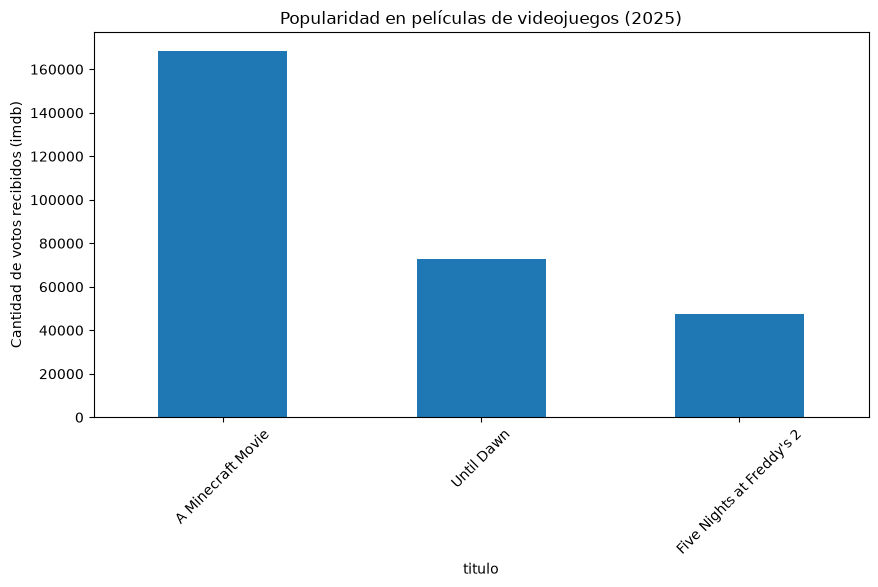

In [7]:
tabla_votos = df_2025.sort_values("votos_imdb", ascending=False).head(10).set_index("titulo")["votos_imdb"]

tabla_votos.plot(kind="bar", figsize=(10, 5), title="Popularidad en películas de videojuegos (2025)")
plt.ylabel("Cantidad de votos recibidos (imdb)")
plt.xticks(rotation=45)
plt.show()

PUNTO 2 ***************************************************************************************************************************

Impacto y tendencias: Evolución del interés antes y después del estreno, picos de búsqueda relacionados con momentos virales

Le pedimos a Google: Traeme el interés de búsqueda de Minecraft Movie (2025-04-04) entre febrero y junio de 2025. 

Google Trends no da cuántas veces la buscaron. Da un número relativo, de 0 a 100:

100 = el día con más búsquedas de todo el período (el pico).
50 = ese día que se buscó la mitad que en el pico.
1 = casi nadie la buscó.

In [23]:
from pytrends.request import TrendReq

pytrends = TrendReq(hl="es-AR", tz=180)
pytrends.build_payload(["Minecraft Movie"], timeframe="2025-02-01 2025-06-30")

tendencia = pytrends.interest_over_time()

#De la tabla, dame desde 10 dias antes y 10 dias despues, solo la columna Minecraft Movie”.
rango = tendencia.loc["2025-03-25":"2025-04-15", "Minecraft Movie"]
rango



date
2025-03-25      8
2025-03-26      8
2025-03-27      9
2025-03-28     11
2025-03-29     13
2025-03-30     15
2025-03-31     20
2025-04-01     22
2025-04-02     28
2025-04-03     46
2025-04-04     81
2025-04-05    100
2025-04-06     91
2025-04-07     56
2025-04-08     41
2025-04-09     40
2025-04-10     32
2025-04-11     37
2025-04-12     50
2025-04-13     44
2025-04-14     30
2025-04-15     24
Name: Minecraft Movie, dtype: int64

In [ ]:
#Dia del pico
rango.idxmax()

#El dia despues del estreno

Timestamp('2025-04-05 00:00:00')

GRAFICO DE INTERES

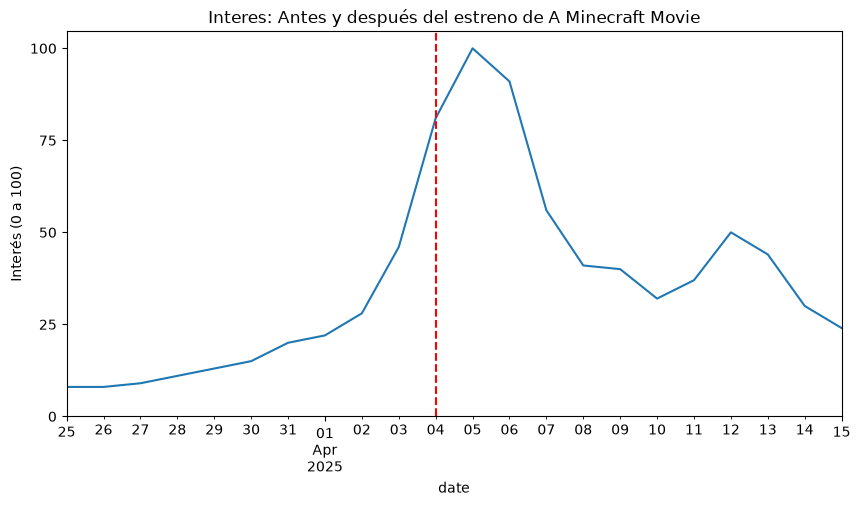

In [33]:
rango.plot(kind="line", figsize=(10, 5), title="Interes: Antes y después del estreno de A Minecraft Movie")
plt.ylabel("Interés (0 a 100)")
plt.xticks(rotation=0)
plt.yticks([0, 25, 50, 75, 100])
plt.axvline(pd.Timestamp("2025-04-04"), color="red", linestyle="--")
plt.show()

MOMENTOS VIRALES:

Comparamos la película con el meme “Chicken Jockey”, una escena viral:

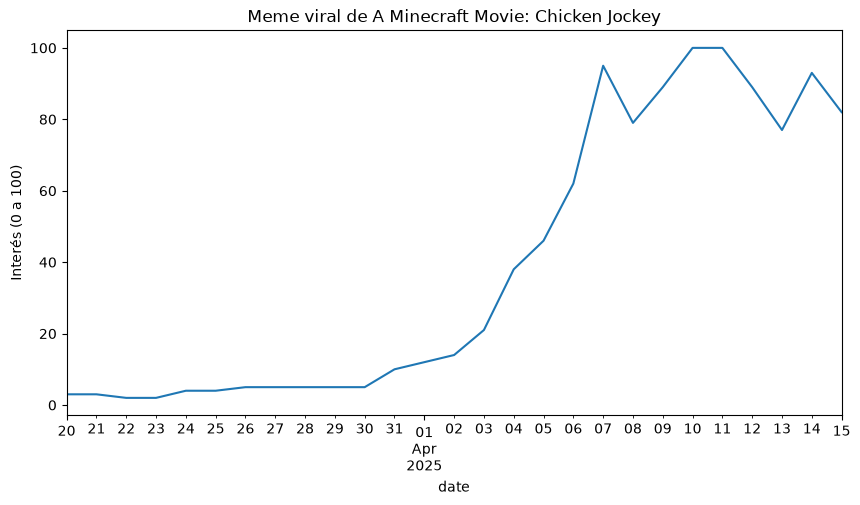

In [39]:
pytrends.build_payload(["Chicken Jockey"], timeframe="2025-03-20 2025-04-15")
meme = pytrends.interest_over_time()

meme["Chicken Jockey"].plot(kind="line", figsize=(10, 5), title="Meme viral de A Minecraft Movie: Chicken Jockey")
plt.ylabel("Interés (0 a 100)")
plt.xticks(rotation=0)
plt.show()

El interés por el meme del Chicken Jockey creció de forma gradual desde el estreno y alcanzó su máximo hacia el 10-11 de abril, coincidiendo con el segundo repunte de interés de la película (12 de abril). Esto SUGIERE que el meme pudo ayudar a sostener el interés.

(Decidí mostrar los gráficos por separado porque los valores de una película y un meme son muy diferentes. Al ponerlos juntos, no se podían apreciar bien los picos de cada uno. Separados, se pueden ver y comparar mejor.)

PUNTO 3 *******************************************************************************************************************

Opinión del público: 
Calificaciones de crítica vs. audiencia, comentarios, sentimiento de las opiniones (positivo/negativo), y principales temas mencionados — presten especial atención a dónde diverge la crítica de la audiencia, porque ahí está el hallazgo más interesante de este caso.

Calificaciones de críticos y espectadores:

#Los criticos es el metascore 
#El público es rating_imdb y rating_tmdb.

    IMDb: sitio web de cine que recopila puntuaciones y opiniones de los espectadores.
    TMDB: base de datos de películas que reúne información, puntuaciones y opiniones de los usuarios.

In [41]:
mc = df[df["titulo"] == "A Minecraft Movie"]
mc[["titulo", "metascore", "rating_imdb", "rating_tmdb"]]

,titulo,metascore,rating_imdb,rating_tmdb
24,A Minecraft Movie,45.0,5.6,6.191


GRAFICO: Criticos vs Espectadores

***  Pase todo a escala de 0 a 100 porque IMDb y TMDB van de 0 a 10 y el metascore de 0 a 100, así que multiplico por 10 para poder compararlos.***

IMDb: sitio web de cine que recopila puntuaciones y opiniones de los espectadores.
TMDB: base de datos de películas que reúne información, puntuaciones y opiniones de los usuarios.

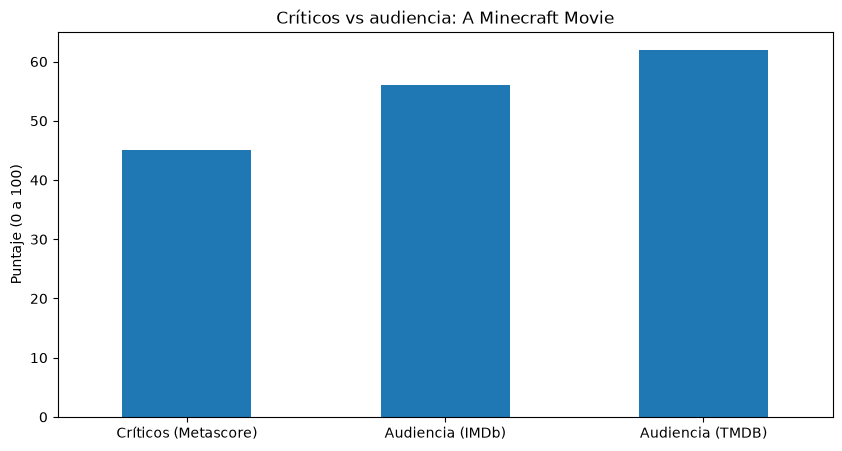

In [45]:
tabla = pd.Series({
    "Críticos (Metascore)": mc["metascore"].iloc[0],
    "Audiencia (IMDb)": mc["rating_imdb"].iloc[0] * 10,
    "Audiencia (TMDB)": mc["rating_tmdb"].iloc[0] * 10
})

tabla.plot(kind="bar", figsize=(10, 5), title="Críticos vs audiencia: A Minecraft Movie")
plt.ylabel("Puntaje (0 a 100)")
plt.xticks(rotation=0)
plt.show()

Los críticos le dieron 45 sobre 100, mientras que los espectadores le dieron entre 56 y 62. Crítica dividida, audiencia más entusiasta.
La audiencia valoró la película mejor que la crítica.

Comentarios positivos y negativos.

In [89]:
import os
import requests
import pandas as pd
from dotenv import load_dotenv

load_dotenv("../.env")
API_KEY = os.getenv("TMDB_API_KEY")

def consultar_tmdb(endpoint, **parametros):
    url = "https://api.themoviedb.org/3" + endpoint
    parametros["api_key"] = API_KEY
    return requests.get(url, params=parametros).json()

In [90]:
print(API_KEY is not None)

True


Nota y opiniones: sentimientos positivos y negativos

In [91]:
df_com = pd.DataFrame(reseñas["results"])
df_com["nota"] = df_com["author_details"].apply(lambda d: d["rating"])

df_com[["author", "nota"]]

#cada reseña tiene la nota que puso el autor

,author,nota
0,tmdb98094809,10.0
1,CinemaSerf,6.0
2,CinemaSerf,6.0
3,Jm_15,NaN
4,Amaly1414,NaN
5,TheRealReviewer,NaN
6,microTato,6.0
7,r96sk,9.0
8,misubisu,8.0
9,johnrose40,9.0


In [103]:
reseñas = consultar_tmdb("/movie/950387/reviews", language="en-US")

df_com = pd.DataFrame(reseñas["results"])
df_com["nota"] = df_com["author_details"].apply(lambda d: d["rating"])
df_com = df_com[["author", "nota", "content"]].drop_duplicates(subset="content")

for i, fila in df_com.iterrows():
    print(i, fila["author"], "| nota:", fila["nota"])
    print(fila["content"])
    print("-----")

0 tmdb98094809 | nota: 10.0
Alright, buckle up, because I just saw a movie that completely blew my mind! Seriously, I'm still buzzing. From the very first scene, I was absolutely hooked, and it didn't let go until the credits rolled.

The story? Oh my gosh, the story! It was so clever and well-crafted. It had twists and turns I never saw coming, but it all made perfect sense in the end. It was like a puzzle that slowly came together, and every piece was perfectly placed. You know when a movie makes you think? This one definitely did that. It wasn't just mindless action or fluff; it had real substance.

And the characters! They were so real and relatable. I felt like I knew them, like I was right there with them on their journey. They had depth, they had flaws, they had moments that made me laugh, and moments that made me want to cry. I was completely invested in what happened to them. The actors did an amazing job bringing them to life. You could feel their emotions through the screen.

In [ ]:

#Manualmente hice la tabla leyendo las reseñas
#hay 11 reseñas

df_com.loc[df_com["author"].isin(["johnrose40", "tmdb98094809", "Jm_15", "microTato", "r96sk", "misubisu", "TheRealReviewer"]), "sentimiento"] = "positivo"

df_com.loc[df_com["author"].isin(["JJ Rosales", "Amaly1414"]), "sentimiento"] = "negativo"

df_com.loc[df_com["author"].isin(["CinemaSerf"]), "sentimiento"] = "neutro"




In [111]:
df_com = df_com.drop_duplicates(subset="author")
df_com[["author", "nota", "sentimiento"]]

,author,nota,sentimiento
0,tmdb98094809,10.0,positivo
1,CinemaSerf,6.0,neutro
3,Jm_15,NaN,positivo
4,Amaly1414,NaN,negativo
5,TheRealReviewer,NaN,positivo
6,microTato,6.0,positivo
7,r96sk,9.0,positivo
8,misubisu,8.0,positivo
9,johnrose40,9.0,positivo
10,JJ Rosales,5.0,negativo


GRAFICO sentimientos de las opiniones (negativo/positivo)

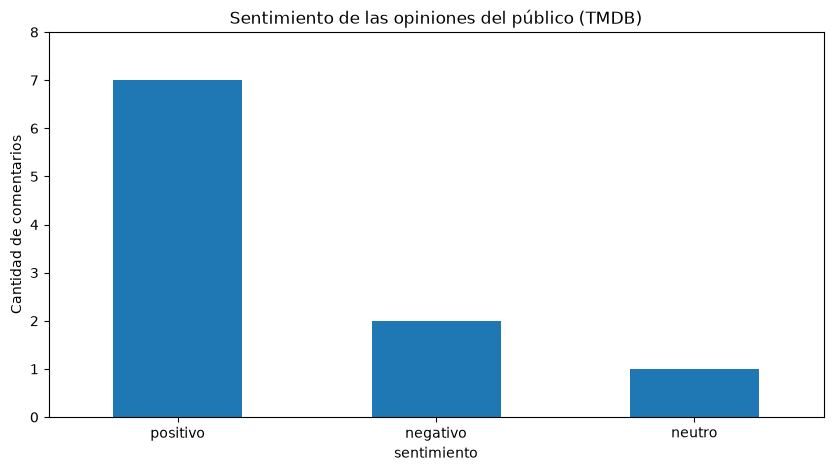

In [123]:
df_com["sentimiento"].value_counts()

df_com["sentimiento"].value_counts().plot(kind="bar", figsize=(10, 5), title="Sentimiento de las opiniones del público (TMDB)")
plt.ylabel("Cantidad de comentarios")
plt.xticks(rotation=0)
plt.ylim(0, 8)
plt.show()

Principales temas mencionados

In [116]:
comunes = ["the", "and", "that", "this", "with", "for", "was", "were", "but", "not", "you", "its", "have", "had", "his", "her", "are", "from", "they", "movie", "film", "just", "like", "very", "about", "there", "what", "when", "will", "would", "more", "than", "into", "some", "even", "also", "who", "all", "can", "out", "one"]

texto = " ".join(df_com["content"]).lower()
palabras = [p.strip(".,!?\"'()") for p in texto.split()]
palabras = [p for p in palabras if len(p) > 3 and p not in comunes]


pd.Series(palabras).value_counts().head(25)

black         8
much          8
really        6
world         6
jack          6
good          6
story         5
made          5
over          5
well          5
momoa         5
minecraft     5
completely    4
think         4
them          4
long          4
time          4
take          4
game          4
solid         4
mind          3
didn't        3
perfect       3
every         3
perfectly     3
Name: count, dtype: int64

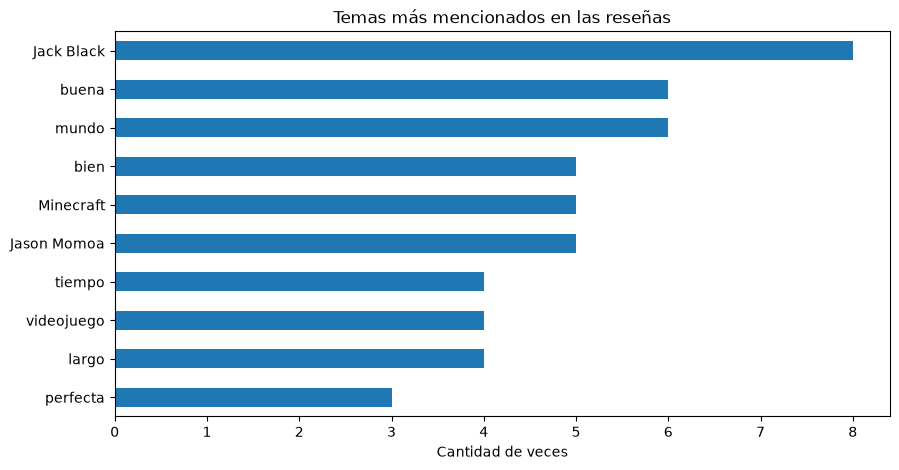

In [124]:
texto = " ".join(df_com["content"]).lower()
palabras = [p.strip(".,!?\"'()") for p in texto.split()]

traduccion = {
    "black": "Jack Black",
    "world": "mundo",
    "good": "buena",
    "well": "bien",
    "momoa": "Jason Momoa",
    "minecraft": "Minecraft",
    "time": "tiempo",
    "long": "largo",
    "game": "videojuego",
    "perfect": "perfecta",
}

temas = pd.Series(palabras).map(traduccion).value_counts().sort_values()

temas.plot(kind="barh", figsize=(10, 5), title="Temas más mencionados en las reseñas")
plt.xlabel("Cantidad de veces")
plt.show()

En este gráfico podemos ver que lo más mencionado en las reseñas es Jack Black, con 8 menciones, así que el público habló mucho de su actuación. Después aparecen “buena” y “mundo”, con 6 cada una, y luego Minecraft, Jason Momoa y “bien”, con 5. Esto muestra que la gente comentó sobre los actores y el mundo de Minecraft y no tanto en torno a la historia en sí. En general las opiniones fueron buenas.

*** Dónde diverge la crítica de la audiencia? ***

La crítica fue más dura que el público. El Metascore fue de 45 sobre 100, mientras que el público le dio 56 en IMDb y 62 en TMDB, o sea entre 11 y 17 puntos más. Además, los espectadores que dejaron reseña en TMDB le pusieron en promedio cerca de 76 sobre 100, una diferencia todavía mayor.

La divergencia está en que los críticos la ven como simple y derivativa, mientras que el público destaca lo divertida que es.

Esa distancia es el hallazgo: una película que los críticos valoraron poco, pero que el público disfrutó más.

*******************************************************************************************************************************************

Objetivo:
Determinar si "A Minecraft Movie" fue una inversión exitosa para CineMetrics y si el patrón (crítica dividida, audiencia entusiasta, fenómeno viral) es replicable o fue un caso puntual.

¿Fue una inversión exitosa para CineMetrics?
Considero que sí fue una inversión exitosa para CineMetrics, porque se logró recuperar más dinero del que se invirtió. Aunque las críticas no fueron muy buenas, al público le gustó y eso permitió que el negocio fuera rentable.


¿Es un patrón replicable o un caso puntual?
No podemos asegurar que este patrón sea replicable, ya que el éxito pudo haber dependido principalmente de la popularidad de la marca Minecraft y de su público familiar y juvenil. Sin embargo, los resultados muestran que el entusiasmo de la audiencia y la viralización pueden ser factores importantes para el éxito de una película. Por lo tanto, si se vuelven a dar estas mismas condiciones en futuras producciones, existe la posibilidad de obtener resultados similares.


El hallazgo mas fuerte de cada uno:

1) Comercial: presupuesto recaudacion etc
Mi hallazgo más fuerte: A Minecraft Movie tuvo un presupuesto de 150 millones de dólares y recaudó aproximadamente 960 millones en taquilla, es decir, más de 6 veces lo que costó producirla. Si la comparamos con otras adaptaciones de videojuegos estrenadas en 2025, como Five Nights at Freddy's 2, que recaudó 238 millones, y Until Dawn, que recaudó 54 millones, podemos ver que Minecraft tuvo un rendimiento comercial muy superior al de sus competidoras.


2) Publico :
Mi hallazgo más fuerte: la crítica le dio 45 sobre 100 y el público entre 56 y 62. 
Es una película que los críticos valoraron poco, para ellos la historia es simple, poco desarrollo de personajes y esta priorizando el espectáculo por encima de la calidad narrativa
En cambio la audiencia la disfruto mas, enfocandoce en el elenco, los momentos divertidos y los sentimientos encontrados al ver una pelicula de su videojuego favorito

3. Viral (interés de búsqueda):
Mi hallazgo más fuerte: el interés de búsqueda tuvo su punto más alto el día despues del estreno, el 5 de abril. Después de una caída, volvió a repuntar el día 10 y 11 , coincidiendo con la viralización del meme del Chicken Jockey. Esto demuestra cómo un fenómeno viral puede volver a despertar o mantener el interés del público por una película.